In [21]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [22]:
df = yf.download("EURUSD=X", start="2010-01-01", end="2024-12-31", interval="1d")
df.columns = df.columns.get_level_values(0)
df = df[["Close"]].dropna()
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price          Close
Date                
2010-01-01  1.438994
2010-01-04  1.442398
2010-01-05  1.436596
2010-01-06  1.440403
2010-01-07  1.431803


In [23]:
df["SMA_short"] = df["Close"].rolling(10).mean()
df["SMA_long"] = df["Close"].rolling(50).mean()
df["SMA_signal"] = (df["SMA_short"] > df["SMA_long"]).astype(int)

delta = df["Close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = -delta.clip(upper=0).rolling(14).mean()
df["RSI"] = 100 - (100/(1+(gain/loss)))
df["RSI_signal"] = (df["RSI"] < 30).astype(int)

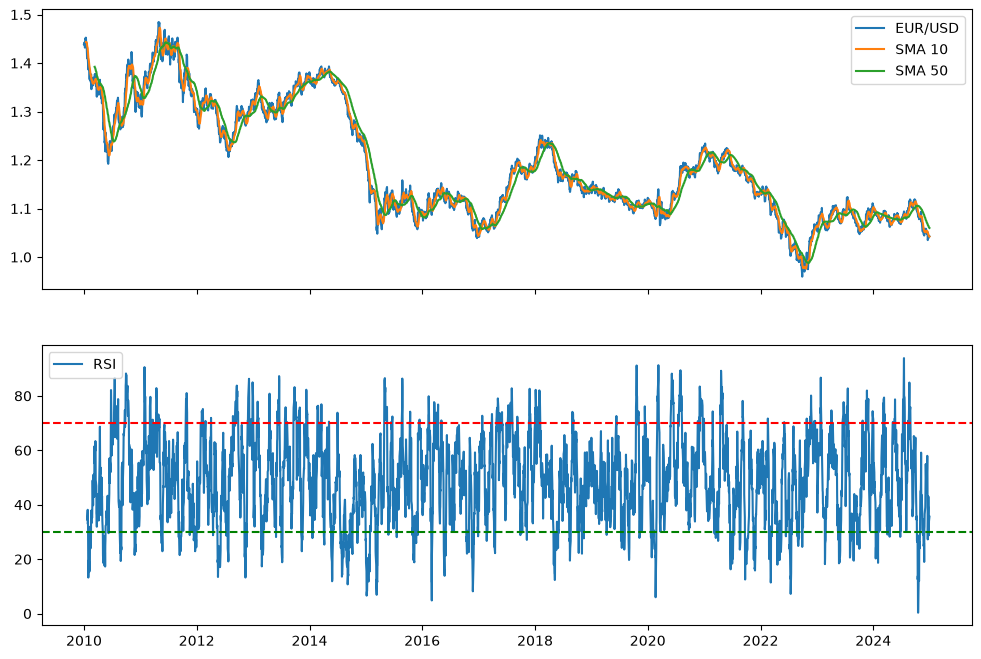

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(df["Close"], label="EUR/USD")
ax1.plot(df["SMA_short"], label="SMA 10")
ax1.plot(df["SMA_long"], label="SMA 50")
ax1.legend()
ax2.plot(df["RSI"], label="RSI")
ax2.axhline(30, color="green", linestyle="--")
ax2.axhline(70, color="red", linestyle="--")
ax2.legend()
plt.show()

In [25]:
log_return = np.log(df["Close"]).diff()
log_return

Date
2010-01-01         NaN
2010-01-04    0.002363
2010-01-05   -0.004031
2010-01-06    0.002647
2010-01-07   -0.005989
                ...   
2024-12-24   -0.002615
2024-12-25   -0.000312
2024-12-26   -0.000291
2024-12-27    0.002270
2024-12-30    0.000594
Name: Close, Length: 3907, dtype: float64

In [26]:
span_years = (df.index[-1] - df.index[0]).days / 365.25
bars_per_year = len(df) / span_years
bars_per_year

260.5498904509768

In [27]:
bars_per_year = 260
dt = 1/bars_per_year

In [28]:
df["log_return"] = np.log(df["Close"]).diff()
df["fwd_return"] = df["log_return"].shift(-1)

print(df[["Close", "log_return", "fwd_return"]].head())

Price          Close  log_return  fwd_return
Date                                        
2010-01-01  1.438994         NaN    0.002363
2010-01-04  1.442398    0.002363   -0.004031
2010-01-05  1.436596   -0.004031    0.002647
2010-01-06  1.440403    0.002647   -0.005989
2010-01-07  1.431803   -0.005989    0.006478


In [29]:
def drift_table(data, col, dt=dt):
    d = data.dropna(subset = ["SMA_long", "RSI", col])
    g = d.groupby(["SMA_signal", "RSI_signal"])[col].agg(["count", "mean", "std"])

    out = pd.DataFrame(index = g.index)

    out["n"] = g["count"]
    out["sigma"] = g["std"] / np.sqrt(dt)
    out["mu"] = g["mean"] / dt + out["sigma"]**2 / 2
    out["se_mu"] = out["sigma"] / np.sqrt(out["n"] * dt)
    out["t_stat"] = out["mu"] / out["se_mu"]
    return out.round(4)

drift_table(df, "fwd_return")
    

n   sigma      mu   se_mu  t_stat
SMA_signal RSI_signal                                      
0          0           1666  0.0864  0.0008  0.0341  0.0244
           1            434  0.0987 -0.0918  0.0764 -1.2019
1          0           1708  0.0840 -0.0094  0.0328 -0.2877
           1             49  0.0599 -0.0333  0.1380 -0.2416

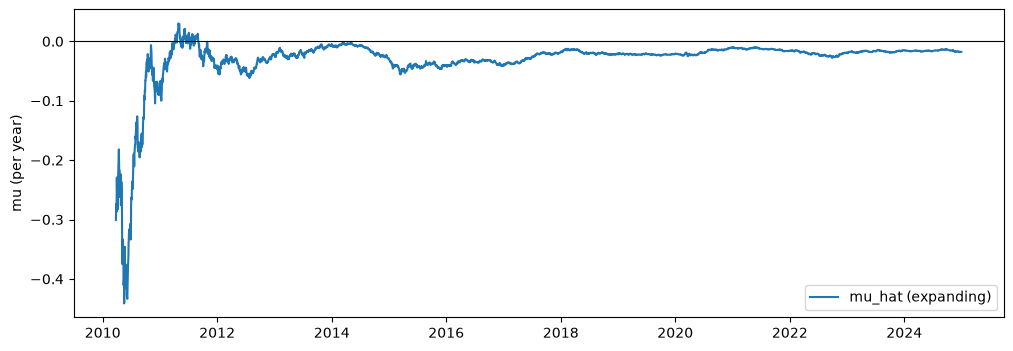

zero crossings: 22


In [30]:
window = log_return.expanding(min_periods=60)

df["sigma_hat"] = window.std() / np.sqrt(dt)
df["mu_hat"]    = window.mean() / dt + df["sigma_hat"]**2 / 2

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["mu_hat"], label="mu_hat (expanding)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("mu (per year)")
ax.legend()
plt.show()

signs = np.sign(df["mu_hat"].dropna())
print("zero crossings:", (signs.diff().abs() > 0).sum())

When using an expanding window the mu crosses zero many times and a rule based purely off of GBM would be confidently wrong. In 2021 it would say to hold even though it is about to crash.

In [31]:
def run_trade(df, entry_i, lam, dt=dt):
    """Enter at day entry_i; exit on the first day the GBM rule says stop."""
    close = df["Close"].to_numpy()
    mu = df["mu_hat"].to_numpy()
    entry_price = close[entry_i]

    # Default: rule never says stop -> forced exit on the last day of data
    exit_i, forced = len(close) - 1, True

    for t in range(entry_i, len(close)):
        # Hold while mu*S > lambda. "not (...)" also exits if mu_hat is NaN
        if not (mu[t] * close[t] > lam):
            exit_i, forced = t, False
            break

    days = exit_i - entry_i
    pnl = close[exit_i] - entry_price
    return {
        "entry_date": df.index[entry_i],
        "exit_date": df.index[exit_i],
        "days_held": days,
        "pnl": pnl,                                # raw price change
        "pnl_net": pnl - lam * days * dt,          # after the holding penalty
        "forced_exit": forced,                     # True = rule never exited on its own
    }

In [32]:
i_2021 = df.index.get_loc(df.loc["2021-03-01":].index[0])
i_2022 = df.index.get_loc(df.loc["2022-06-01":].index[0])
print(run_trade(df, i_2021, lam=0.01))
print(run_trade(df, i_2022, lam=0.01))

{'entry_date': Timestamp('2021-03-01 00:00:00'), 'exit_date': Timestamp('2021-03-01 00:00:00'), 'days_held': 0, 'pnl': np.float64(0.0), 'pnl_net': np.float64(0.0), 'forced_exit': False}
{'entry_date': Timestamp('2022-06-01 00:00:00'), 'exit_date': Timestamp('2022-06-01 00:00:00'), 'days_held': 0, 'pnl': np.float64(0.0), 'pnl_net': np.float64(0.0), 'forced_exit': False}


In [33]:
valid = df["mu_hat"].notna() & df["SMA_long"].notna()   # skip warm-up period

sma_cross = (df["SMA_signal"].diff() == 1) & valid       # 0 -> 1 switch
rsi_cross = (df["RSI_signal"].diff() == 1) & valid       # RSI first drops below 30

# Entry = the day after the signal (positions in the DataFrame, not dates)
sma_entries = [df.index.get_loc(d) + 1 for d in df.index[sma_cross] if df.index.get_loc(d) + 1 < len(df)]
rsi_entries = [df.index.get_loc(d) + 1 for d in df.index[rsi_cross] if df.index.get_loc(d) + 1 < len(df)]

print("SMA entries:", len(sma_entries))
print("RSI entries:", len(rsi_entries))

SMA entries: 54
RSI entries: 112


In [34]:
TRAIN_END="2019-12-31"

def split(entries):
    train = [i for i in entries if df.index[i] <= pd.Timestamp(TRAIN_END)]
    test  = [i for i in entries if df.index[i] >  pd.Timestamp(TRAIN_END)]
    return train, test

sma_train, sma_test = split(sma_entries)
rsi_train, rsi_test = split(rsi_entries)
print("SMA:", len(sma_train), "train /", len(sma_test), "test")
print("RSI:", len(rsi_train), "train /", len(rsi_test), "test")

SMA: 39 train / 15 test
RSI: 65 train / 47 test


In [35]:
def fixed_trade(df, entry_i, n_days):
    """Baseline: hold exactly n_days, no rule."""
    close = df["Close"].to_numpy()
    exit_i = min(entry_i + n_days, len(close) - 1)
    return {"days_held": exit_i - entry_i, "pnl": close[exit_i] - close[entry_i], "forced_exit": False}

def summarize(trades, label):
    t = pd.DataFrame(trades)
    pips = t["pnl"] * 10_000          # 1 pip = 0.0001 in EUR/USD; easier to read than 0.00xx
    return {
        "exit_rule":   label,
        "trades":      len(t),
        "mean_pips":   round(pips.mean(), 1),
        "se_pips":     round(pips.std() / np.sqrt(len(t)), 1),   # same idea as se_mu
        "win_rate":    round((t["pnl"] > 0).mean(), 2),
        "median_days": t["days_held"].median(),
        "pct_0day":    round((t["days_held"] == 0).mean(), 2),   # rule said "don't hold"
        "pct_forced":  round(t["forced_exit"].mean(), 2),        # rule never exited
    }

def backtest(df, entries, lams=(0, 0.001, 0.005, 0.01, 0.02, 0.05), fixed=(5, 10, 20)):
    rows  = [summarize([run_trade(df, i, lam) for i in entries], f"GBM λ={lam}") for lam in lams]
    rows += [summarize([fixed_trade(df, i, n) for i in entries], f"Fixed {n}d") for n in fixed]
    return pd.DataFrame(rows).set_index("exit_rule")

pd.set_option("display.width", 200)
print("=== SMA entries ===")
print(backtest(df, sma_entries))
print("\n=== RSI entries ===")
print(backtest(df, rsi_entries))

=== SMA entries ===
             trades  mean_pips  se_pips  win_rate  median_days  pct_0day  pct_forced
exit_rule                                                                           
GBM λ=0          54      -16.3      9.2      0.00          0.0      0.93         0.0
GBM λ=0.001      54      -16.3      9.2      0.00          0.0      0.93         0.0
GBM λ=0.005      54      -12.8      8.5      0.00          0.0      0.94         0.0
GBM λ=0.01       54       -5.0      5.0      0.00          0.0      0.98         0.0
GBM λ=0.02       54       -1.6      1.6      0.00          0.0      0.98         0.0
GBM λ=0.05       54        0.0      0.0      0.00          0.0      1.00         0.0
Fixed 5d         54      -10.6     19.8      0.48          5.0      0.00         0.0
Fixed 10d        54       -5.8     28.5      0.48         10.0      0.00         0.0
Fixed 20d        54      -28.2     39.7      0.44         20.0      0.00         0.0

=== RSI entries ===
             trades  mea

This stopping rule is fully determined by our predicted mu and can only exit after a decline. This model underperforms and from here on we will need a model like the regime-switching one where the mu is estimated based off of the perceived regime or maybe from LLM sentiment.

In [1]:
is_train = df.index <= pd.Timestamp(TRAIN_END)
mu = df["mu_hat"]

print("Share of days with mu_hat > 0")
print("  train:", round((mu[is_train].dropna() > 0).mean(), 2))
print("  test: ", round((mu[~is_train].dropna() > 0).mean(), 2))

NameError: name 'df' is not defined

In [ ]:
groups = {
    ("SMA", "train"): sma_train,
    ("SMA", "test"):  sma_test,
    ("RSI", "train"): rsi_train,
    ("RSI", "test"):  rsi_test,
}

tables = []
for (signal, part), entries in groups.items():
    t = backtest(df, entries)
    t["signal"] = signal
    t["split"] = part
    tables.append(t)

results = pd.concat(tables).reset_index().set_index(["signal", "split", "exit_rule"])
results